

# **Mini Project: Evaluating Clustering Before and After PCA**

### **Movie Clustering Using Genres and Audience Reception**

This project explores movie clustering based on genres and audience reception using K-Means clustering. It examines the impact of Principal Component Analysis (PCA) on clustering performance by comparing cluster separation, structure, and interpretability before and after dimensionality reduction.


#### **Research Question**
How do genre combinations and audience reception relate to movie clusters, and how much does two-component PCA change the clustering results?

#### **Dataset**
[Kaggle — TMDB Top 10,000 Movies Dataset (2026)](https://www.kaggle.com/datasets/dhritisisodia/tmdb-top-10000-movies-dataset-2026)

### Team Members

- Fay
- Ghadi
- Wasan
- Mohamad

## **0. Import libraries**

In [ ]:
import ast
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

## 1. **Load and Understand the Dataset**

In [ ]:
movies = pd.read_csv("TMDB_Top_10000_Movies_2026.csv")

movies.head()

,Unnamed: 0,genre_ids,id,original_language,overview,popularity,release_date,title,vote_average,vote_count
0,0,"[18, 80]",278,en,Imprisoned in the 1940s for the double murder ...,30.8191,1994-09-23,The Shawshank Redemption,8.716,29721
1,1,"[18, 80]",238,en,"Spanning the years 1945 to 1955, a chronicle o...",36.4215,1972-03-14,The Godfather,8.687,22451
2,2,"[18, 80]",240,en,In the continuing saga of the Corleone crime f...,17.5941,1974-12-20,The Godfather Part II,8.571,13586
3,3,"[18, 36, 10752]",424,en,The true story of how businessman Oskar Schind...,18.6937,1993-12-15,Schindler's List,8.567,17106
4,4,[18],389,en,The defense and the prosecution have rested an...,13.0084,1957-04-10,12 Angry Men,8.555,9741


In [ ]:
print("Dataset shape:", movies.shape)
movies.info()

Dataset shape: (10000, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         10000 non-null  int64  
 1   genre_ids          10000 non-null  object 
 2   id                 10000 non-null  int64  
 3   original_language  10000 non-null  object 
 4   overview           9998 non-null   object 
 5   popularity         10000 non-null  float64
 6   release_date       9997 non-null   object 
 7   title              10000 non-null  object 
 8   vote_average       10000 non-null  float64
 9   vote_count         10000 non-null  int64  
dtypes: float64(2), int64(3), object(5)
memory usage: 781.4+ KB


In [ ]:
movies.columns.tolist()

['Unnamed: 0',
 'genre_ids',
 'id',
 'original_language',
 'overview',
 'popularity',
 'release_date',
 'title',
 'vote_average',
 'vote_count']

In [ ]:
#Missing Values
movies.isnull().sum()

,0
Unnamed: 0,0
genre_ids,0
id,0
original_language,0
overview,2
popularity,0
release_date,3
title,0
vote_average,0
vote_count,0


In [ ]:
#Zeros in the numerical columns
numerical_cols = ["vote_average", "vote_count", "popularity"]

(movies[numerical_cols] == 0).sum()

,0
vote_average,0
vote_count,0
popularity,0


In [ ]:
#Duplicate Movies
print("Duplicate movies:", movies["id"].duplicated().sum())

Duplicate movies: 36


In [ ]:
movies.describe()

,Unnamed: 0,id,popularity,vote_average,vote_count
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000
mean,4999.50000,2.252508e+05,4.280559,6.729167,2077.979600
std,2886.89568,2.991634e+05,7.960604,0.660076,3318.455958
min,0.00000,2.000000e+00,0.003200,5.400000,300.000000
25%,2499.75000,1.032975e+04,1.776575,6.212750,473.000000
50%,4999.50000,4.162000e+04,2.855200,6.700000,868.000000
75%,7499.25000,4.033328e+05,4.874800,7.208000,2077.250000
max,9999.00000,1.472638e+06,340.838100,8.716000,38859.000000


In [ ]:
#To understand how genre are represnted
movies[["title", "genre_ids"]].head(10)

,title,genre_ids
0,The Shawshank Redemption,"[18, 80]"
1,The Godfather,"[18, 80]"
2,The Godfather Part II,"[18, 80]"
3,Schindler's List,"[18, 36, 10752]"
4,12 Angry Men,[18]
5,Spirited Away,"[16, 10751, 14]"
6,The Dark Knight,"[28, 80, 53]"
7,Dilwale Dulhania Le Jayenge,"[35, 18, 10749]"
8,The Green Mile,"[14, 18, 80]"
9,Parasite,"[35, 53, 18]"


The dataset stores movie genres as lists of numerical IDs rather than descriptive genre names. Each movie may contain multiple genre IDs, representing its combination of genres. These values must be converted into readable genre names and encoded into numerical indicator columns before being used in K-Means clustering.

## **2. Data Cleaning and Preprocessing**


In [ ]:
#Preserve the original dataset before cleaning
df = movies.copy()

In [ ]:
#Remove duplicate movie IDs to avoid counting the same movie more than once
df = df.drop_duplicates(subset="id").copy()

In [ ]:
print("Before cleaning:", len(df))

#Remove missing values and invalid audience records
df = df.dropna(subset=["genre_ids","vote_average","vote_count","popularity","release_date"])

df = df[
    (df["vote_count"] > 0) &
    (df["vote_average"] > 0) &
    (df["popularity"] >= 0)
].copy()

print("After cleaning:", len(df))

Before cleaning: 9964
After cleaning: 9961


In [ ]:
#Convert release dates into numerical years
df["release_date"] = pd.to_datetime(
    df["release_date"],
    errors="coerce"
)

df["release_year"] = df["release_date"].dt.year

df = df.dropna(subset=["release_year"])

df["release_year"] = df["release_year"].astype(int)

In [ ]:
genre_map = {
    28: "Action", 12: "Adventure", 16: "Animation", 35: "Comedy",
    80: "Crime", 99: "Documentary", 18: "Drama", 10751: "Family",
    14: "Fantasy", 36: "History", 27: "Horror", 10402: "Music",
    9648: "Mystery", 10749: "Romance", 878: "Science Fiction",
    10770: "TV Movie", 53: "Thriller", 10752: "War", 37: "Western"
}

#Convert stored genre strings into  lists
def parse_genres(value):
    if isinstance(value, list):
        return value
    if isinstance(value, str):
        return ast.literal_eval(value)
    return []

df["genre_list"] = df["genre_ids"].apply(parse_genres)

df["genre_names"] = df["genre_list"].apply(
    lambda ids: [genre_map.get(int(i), f"Unknown ({i})") for i in ids]
)

df[["title", "genre_ids", "genre_names"]].head()

,title,genre_ids,genre_names
0,The Shawshank Redemption,"[18, 80]","[Drama, Crime]"
1,The Godfather,"[18, 80]","[Drama, Crime]"
2,The Godfather Part II,"[18, 80]","[Drama, Crime]"
3,Schindler's List,"[18, 36, 10752]","[Drama, History, War]"
4,12 Angry Men,[18],[Drama]


In [ ]:
#Convert genres into binary columns so movies can belong to multiple genres
genre_columns = (df["genre_names"].str.join("|").str.get_dummies(sep="|"))

genre_columns.head()

,Action,Adventure,Animation,Comedy,Crime,Drama,Family,Fantasy,History,Horror,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western
0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0


In [ ]:
#Reduce the influence of extremely large vote counts and popularity values

df["log_vote_count"] = np.log1p(df["vote_count"])
df["log_popularity"] = np.log1p(df["popularity"])

In [ ]:
#Separate audience features and genre features before scaling

numeric_features = ["vote_average","log_vote_count","log_popularity","release_year"]

X_numeric = df[numeric_features].copy()

X_genres = genre_columns.copy()

print("Numerical features:", X_numeric.shape[1])
print("Genre features:", X_genres.shape[1])

Numerical features: 4
Genre features: 18


In [ ]:
#Standardize features so different numerical scales do not distort distances

numeric_scaler = StandardScaler()
genre_scaler = StandardScaler()

X_numeric_scaled = numeric_scaler.fit_transform(X_numeric)
X_genres_scaled = genre_scaler.fit_transform(X_genres)

In [ ]:
#Balance genres and audience features so neither group dominates due to its number of columns
X_scaled = np.column_stack([
    X_numeric_scaled / np.sqrt(X_numeric.shape[1]),
    X_genres_scaled / np.sqrt(X_genres.shape[1])
])

print("Final model shape:", X_scaled.shape)

Final model shape: (9961, 22)


Missing and invalid audience records were handled to ensure the clustering analysis used movies with meaningful rating information. Release dates were converted into numerical years, and genre IDs were mapped to their corresponding names using TMDB's official genre reference.

Multi-hot encoding was applied to represent movies with multiple genres. Highly skewed vote counts and popularity values were log-transformed, followed by standardization and feature-group balancing to prepare the data for distance-based clustering.

## **3. K-Means Clustering Before PCA**

In [ ]:
#Evaluate cluster separation to help choose suitable K values by silhouette scores
k_values = range(2, 9)
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    silhouette_scores.append(
        silhouette_score(X_scaled, labels, sample_size=2000, random_state=42)
    )

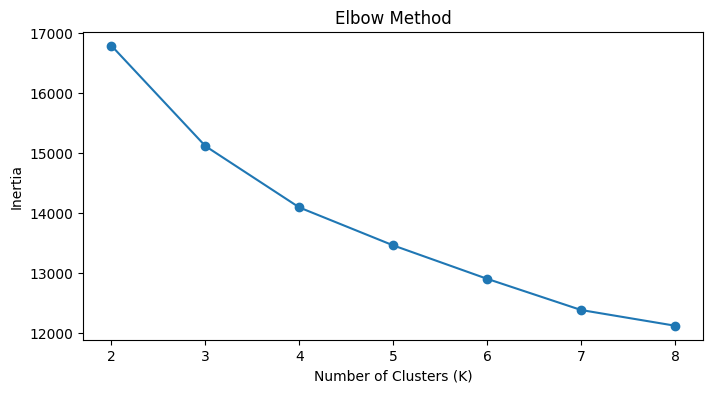

In [ ]:
#Elbow Method
inertias = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_values, inertias, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.show()

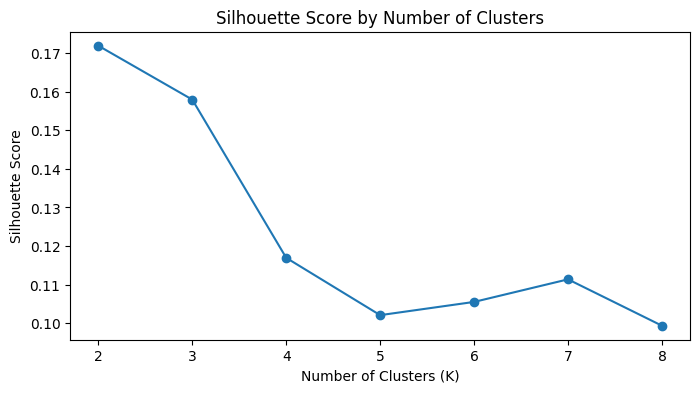

In [ ]:
#Compare silhouette scores across different numbers of clusters
plt.figure(figsize=(8, 4))

plt.plot(k_values, silhouette_scores, marker="o")
plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

plt.show()

In [ ]:
#Fit K-Means using two different levels of clustering detail
kmeans_2_before = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_2_before = kmeans_2_before.fit_predict(X_scaled)

kmeans_7_before = KMeans(n_clusters=7, random_state=42, n_init=10)
labels_7_before = kmeans_7_before.fit_predict(X_scaled)

In [ ]:
#Evaluate cluster separation for both configurations before PCA
results_before = pd.DataFrame({
    "K": [2, 7],
    "Silhouette Score": [
        silhouette_score(X_scaled, labels_2_before, sample_size=2000, random_state=42),
        silhouette_score(X_scaled, labels_7_before, sample_size=2000, random_state=42)
    ]
})

results_before.round(3)

,K,Silhouette Score
0,2,0.172
1,7,0.111


### K-Means Before PCA Conclusion

The Silhouette Score analysis shows that K = 2 achieves the highest score (approximately 0.172), indicating the strongest cluster separation among the tested configurations. Although K = 7 has a lower score (approximately 0.111), it represents a local peak compared with neighboring K values.

Therefore, K = 2 and K = 7 were selected for further analysis. K = 2 allows the exploration of broad movie groupings, while K = 7 provides an opportunity to investigate more detailed patterns in genres and audience reception.

The relatively low Silhouette Scores suggest that the movie clusters are not strongly separated in the original feature space. These results establish a baseline for evaluating how PCA affects clustering performance.

## **4. Principal Component Analysis (PCA)**

In [ ]:
#Reduce the standardized features to two principal components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X_scaled.shape)
print("PCA shape:", X_pca.shape)

Original shape: (9961, 22)
PCA shape: (9961, 2)


In [ ]:
#Measure how much variance is retained by the two principal components
explained_variance = pca.explained_variance_ratio_

print("PC1:", round(explained_variance[0] * 100, 2), "%")
print("PC2:", round(explained_variance[1] * 100, 2), "%")
print("Total explained variance:", round(explained_variance.sum() * 100, 2), "%")

PC1: 23.49 %
PC2: 15.73 %
Total explained variance: 39.23 %


PCA reduced the dataset from 22 features to 2 principal components while preserving all 9,961 movies. PC1 explains 23.49% of the variance, while PC2 explains 15.73%, resulting in a total explained variance of **39.23%**.



## **5. K-Means Clustering After PCA**
- **K=2:** Tests whether movies split into broad profiles such as high versus low audience engagement.
- **K=7:** Tests whether more detailed groups emerge, potentially involving genre mixtures and ratings.


In [ ]:
#Apply K-Means to the PCA-reduced data using K=2 and K=7
kmeans_2_after = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_2_after = kmeans_2_after.fit_predict(X_pca)

kmeans_7_after = KMeans(n_clusters=7, random_state=42, n_init=10)
labels_7_after = kmeans_7_after.fit_predict(X_pca)

In [ ]:
#Measure cluster separation after reducing the features to two components
results_after = pd.DataFrame({
    "K": [2, 7],
    "Silhouette Score": [
        silhouette_score(X_pca, labels_2_after, sample_size=2000, random_state=42),
        silhouette_score(X_pca, labels_7_after, sample_size=2000, random_state=42)
    ]
})

results_after.round(3)

,K,Silhouette Score
0,2,0.405
1,7,0.345


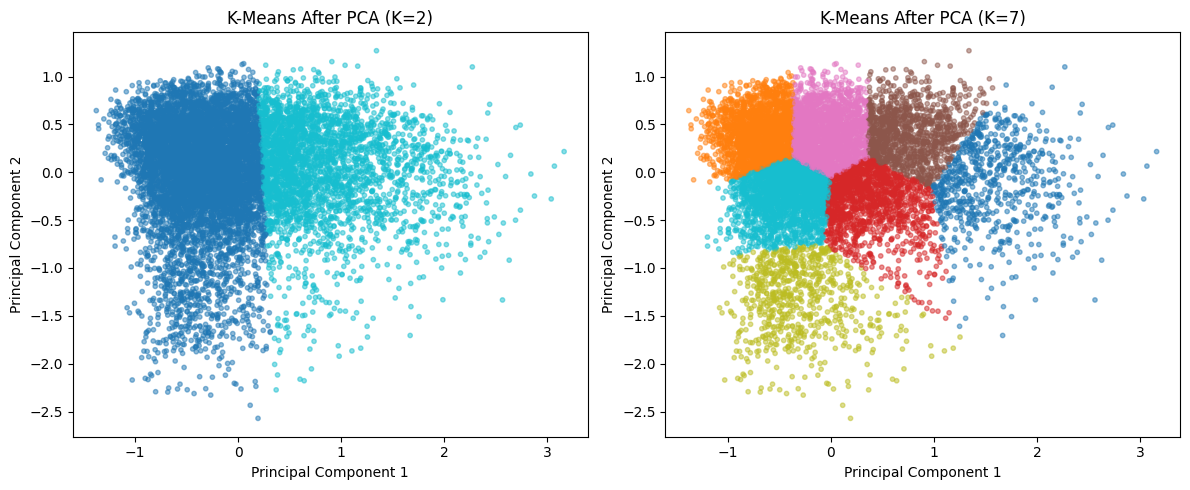

In [ ]:
#Visualize movie clusters in the two-dimensional PCA space
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=labels_2_after, cmap="tab10", s=10, alpha=0.5
)
axes[0].set_title("K-Means After PCA (K=2)")

axes[1].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=labels_7_after, cmap="tab10", s=10, alpha=0.5
)
axes[1].set_title("K-Means After PCA (K=7)")

for ax in axes:
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

### K-Means After PCA  Conclusion

After PCA, K = 2 achieved a Silhouette Score of **0.405**, compared with **0.345** for K = 7, indicating stronger cluster separation in the reduced space.

The visualizations show that K = 2 creates two broad groups, while K = 7 produces more detailed clusters with relatively clear boundaries.

Both configurations show improved separation in the 2D PCA space compared with their original-space scores. However, since PCA retains only **39.23% of the original variance**, the higher scores do not necessarily indicate better clustering of the original data.

## **6. K-Means Clustering: Before vs. After PCA**

In [ ]:
#Compare cluster separation before and after PCA
comparison = pd.DataFrame({
    "K": [2, 7],
    "Before PCA": [
        silhouette_score(X_scaled, labels_2_before, sample_size=2000, random_state=42),
        silhouette_score(X_scaled, labels_7_before, sample_size=2000, random_state=42)
    ],
    "After PCA": [
        silhouette_score(X_pca, labels_2_after, sample_size=2000, random_state=42),
        silhouette_score(X_pca, labels_7_after, sample_size=2000, random_state=42)
    ]
})

comparison.round(3)

,K,Before PCA,After PCA
0,2,0.172,0.405
1,7,0.111,0.345


In [ ]:
#Measure how much cluster assignments changed after PCA
ari_2 = adjusted_rand_score(labels_2_before, labels_2_after)
ari_7 = adjusted_rand_score(labels_7_before, labels_7_after)

ari_results = pd.DataFrame({
    "K": [2, 7],
    "ARI": [ari_2, ari_7]
})

ari_results.round(3)

#Close to 1: Most cluster assignments are consistent.
#Close to 0: Agreement is approximately what we'd expect by chance.
#Negative: Agreement is worse than chance.

,K,ARI
0,2,0.970
1,7,0.338


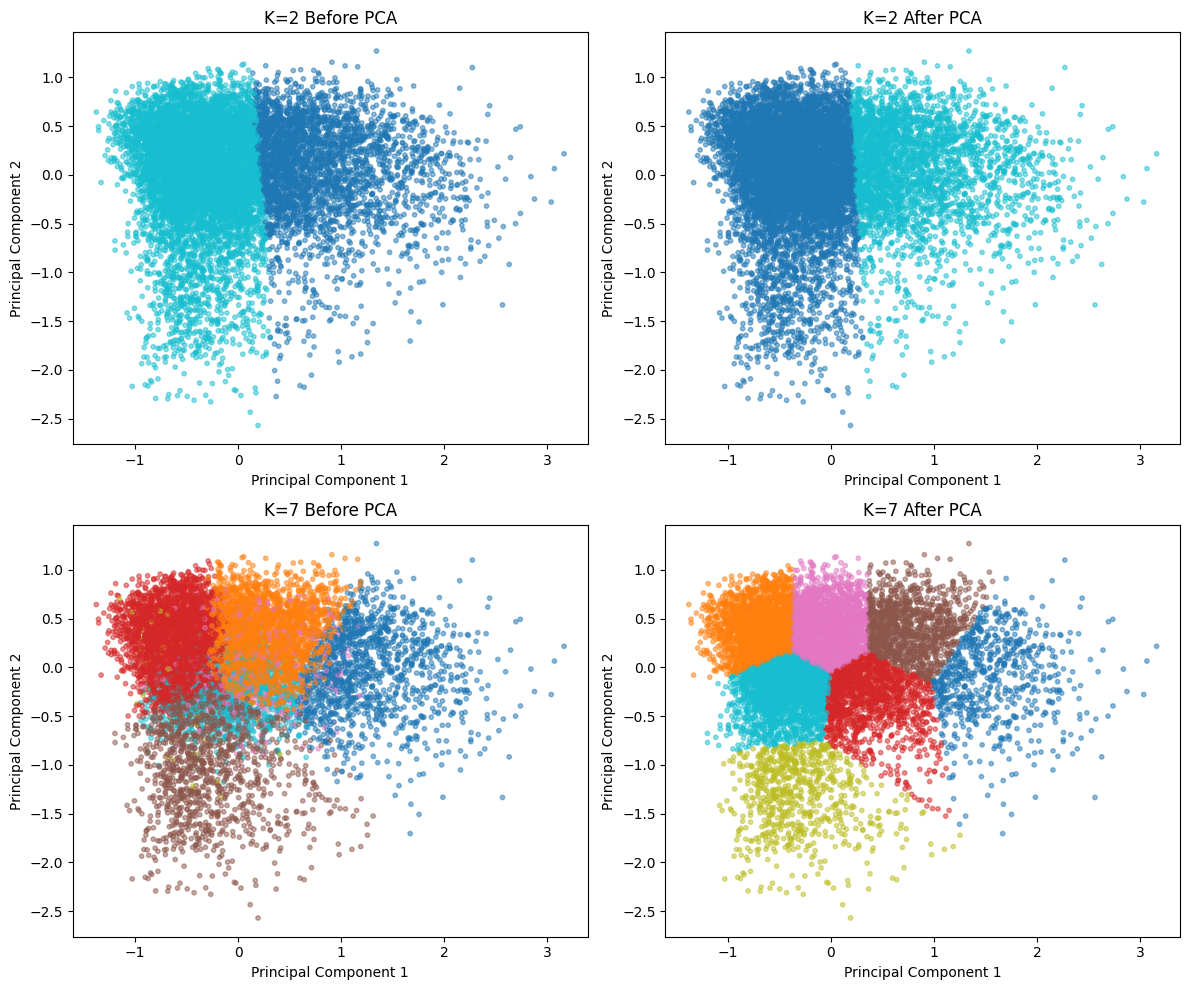

In [ ]:
#Compare original-space and PCA-space cluster assignments in 2D
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

experiments = [
    (labels_2_before, "K=2 Before PCA"),
    (labels_2_after, "K=2 After PCA"),
    (labels_7_before, "K=7 Before PCA"),
    (labels_7_after, "K=7 After PCA")
]

for ax, (labels, title) in zip(axes.flat, experiments):
    ax.scatter(
        X_pca[:, 0], X_pca[:, 1],
        c=labels, cmap="tab10",
        s=10, alpha=0.5
    )
    ax.set_title(title)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

### Final Conclusion  Before vs. After PCA

PCA reduced the dataset from 22 features to 2 principal components, retaining **39.23% of the original variance**.

For **K = 2**, cluster assignments remained highly consistent before and after PCA, with an ARI of **0.970**. This suggests that the broad movie groupings were largely preserved despite dimensionality reduction.

For **K = 7**, the ARI decreased to **0.338**, indicating substantial changes in cluster assignments. Although the visualization became clearer after PCA, the detailed clusters were less stable.

Silhouette Scores also increased in the reduced space, reaching **0.405 for K = 2** and **0.345 for K = 7**. However, these improvements do not necessarily indicate better clustering because the scores were calculated in different feature spaces.

**Overall, K = 2 appears more suitable for preserving stable movie groupings**, while K = 7 offers more detailed visual patterns at the cost of assignment stability. PCA improves two-dimensional visualization but may lose important information, making the original feature space preferable when retaining detailed movie characteristics is the priority.

## **7. Cluster Interpretation**

In [ ]:
#Compare ratings, vote counts, and popularity across movie clusters
audience_features = ["vote_average", "vote_count", "popularity"]

for k, labels in [(2, labels_2_after), (7, labels_7_after)]:
    print(f"\nK = {k}: Audience Characteristics")

    audience = df[audience_features].copy()
    audience["Cluster"] = labels

    display(
        audience.groupby("Cluster")[audience_features]
        .agg(["mean", "median"])
        .round(2)
    )



K = 2: Audience Characteristics


vote_average        vote_count         popularity       
                mean median       mean  median       mean median
Cluster                                                         
0               6.60   6.57     774.07   593.0       2.39   2.13
1               7.03   7.02    5049.62  3454.5       8.51   6.25


K = 7: Audience Characteristics


vote_average        vote_count         popularity       
                mean median       mean  median       mean median
Cluster                                                         
0               7.54   7.53   10940.00  9757.0      15.99  11.52
1               6.05   6.01     514.44   445.0       1.70   1.61
2               7.28   7.30    2132.06  1777.5       4.26   4.04
3               6.61   6.60    4136.60  3739.5       7.84   6.66
4               6.32   6.31    1294.56  1139.0       3.69   3.44
5               7.46   7.46     824.15   586.5       2.27   1.93
6               6.89   6.90     597.52   504.0       1.98   1.84

In [ ]:
#Identify the most common genres within each cluster
for k, labels in [(2, labels_2_after), (7, labels_7_after)]:
    print(f"\nK = {k}: Most Common Genres")

    genre_summary = genre_columns.copy()
    genre_summary["Cluster"] = labels

    genre_percentages = (
        genre_summary.groupby("Cluster").mean() * 100
    )

    for cluster in genre_percentages.index:
        print(f"\nCluster {cluster}")
        display(
            genre_percentages.loc[cluster]
            .sort_values(ascending=False)
            .head(5)
            .round(1)
        )



K = 2: Most Common Genres

Cluster 0


,0
Drama,49.8
Comedy,39.1
Thriller,25.9
Romance,19.3
Action,18.1



Cluster 1


,1
Drama,39.3
Action,34.2
Comedy,28.7
Thriller,28.4
Adventure,28.1



K = 7: Most Common Genres

Cluster 0


,0
Action,40.2
Adventure,38.9
Drama,38.5
Science Fiction,24.9
Thriller,23.3


... (8 outputs left out)


Cluster 5


,5
Drama,62.0
Comedy,29.2
Romance,24.3
Crime,16.3
Thriller,15.6



Cluster 6


,6
Drama,61.3
Comedy,39.4
Romance,22.3
Thriller,17.3
Crime,15.2


In [ ]:
#Show popular movie examples from each cluster
for k, labels in [(2, labels_2_after), (7, labels_7_after)]:
    print(f"\nK = {k}: Movie Examples")

    examples = df[
        ["title", "genre_names", "vote_average", "vote_count"]
    ].copy()

    examples["Cluster"] = labels

    for cluster in sorted(examples["Cluster"].unique()):
        print(f"\nCluster {cluster}")

        display(
            examples[examples["Cluster"] == cluster]
            .sort_values("vote_count", ascending=False)
            .head(3)
        )



K = 2: Movie Examples

Cluster 0


,title,genre_names,vote_average,vote_count,Cluster
6525,X-Men: The Last Stand,"[Adventure, Action, Science Fiction, Thriller]",6.416,10202,0
5767,The Lost World: Jurassic Park,"[Adventure, Action, Science Fiction]",6.561,9044,0
7719,Jurassic Park III,"[Adventure, Action, Thriller, Science Fiction]",6.172,7698,0



Cluster 1


,title,genre_names,vote_average,vote_count,Cluster
14,Interstellar,"[Adventure, Drama, Science Fiction]",8.467,38859,1
41,Inception,"[Action, Science Fiction, Adventure]",8.370,38679,1
352,The Avengers,"[Science Fiction, Action, Adventure]",7.941,35871,1



K = 7: Movie Examples

Cluster 0


,title,genre_names,vote_average,vote_count,Cluster
14,Interstellar,"[Adventure, Drama, Science Fiction]",8.467,38859,0
41,Inception,"[Action, Science Fiction, Adventure]",8.370,38679,0
352,The Avengers,"[Science Fiction, Action, Adventure]",7.941,35871,0


... (8 outputs left out)


Cluster 5


,title,genre_names,vote_average,vote_count,Cluster
18,Grave of the Fireflies,"[Animation, Drama, War]",8.443,6353,5
3466,Bambi,"[Animation, Drama, Family]",7.010,5941,5
308,Citizen Kane,"[Mystery, Drama]",7.982,5928,5



Cluster 6


,title,genre_names,vote_average,vote_count,Cluster
7972,Kindergarten Cop,[Comedy],6.116,2727,6
7843,Return,"[Horror, Fantasy, Romance]",6.143,2699,6
1457,Ip Man 2,"[Action, History, Drama]",7.463,2435,6


### Cluster Interpretation  K = 2

K = 2 separates movies into two broad groups, primarily based on audience reception and engagement.

- **Cluster 0 — Lower Engagement:** Movies have an average rating of 6.60, approximately 774 votes, and popularity of 2.39. Drama (49.8%) and Comedy (39.1%) are the most common genres.
- **Cluster 1 — Higher Engagement:** Movies have a higher average rating of 7.03, approximately 5,050 votes, and popularity of 8.51. Drama (39.3%), Action (34.2%), and Adventure (28.1%) are prominent genres.

For example, *Interstellar*, *Inception*, and *The Avengers* belong to the higher-engagement cluster, while *X-Men: The Last Stand* and *Jurassic Park III* appear in the lower-engagement cluster.

Overall, K = 2 reveals a broad distinction between movies with higher and lower audience engagement rather than separating movies strictly by genre.

### Cluster Interpretation  K = 7

K = 7 reveals more detailed movie profiles, combining differences in audience engagement, ratings, and genre composition.

| Cluster | Characteristics |
|---|---|
| **0 — Highly Popular Movies** | Highest average vote count (10,940), popularity (15.99), and rating (7.54). Action and Adventure are prominent. |
| **1 — Lower-Rated, Low-Engagement Movies** | Lowest average rating (6.05) and popularity (1.70). Comedy and Drama are common. |
| **2 — Well-Rated Movies** | Average rating of 7.28 and moderate engagement, with Drama appearing in 63.1% of movies. |
| **3 — Popular, Moderately Rated Movies** | Relatively high vote counts (4,137) and popularity (7.84), with Action, Comedy, and Thriller prominent. |
| **4 — Lower-Rated, Moderate-Engagement Movies** | Average rating of 6.32 and popularity of 3.69, with Comedy, Thriller, and Drama common. |
| **5 — Highly Rated, Less Popular Movies** | High average rating (7.46) but relatively low vote counts (824). Drama is dominant at 62.0%. |
| **6 — Moderately Rated, Low-Engagement Movies** | Average rating of 6.89 and low popularity (1.98), with Drama and Comedy dominant. |

These results show that movies with similar genres can belong to different clusters depending on their audience characteristics. For example, Clusters 2, 5, and 6 are all strongly associated with Drama but differ considerably in ratings and engagement.

### Key Insight

The K = 2 experiment identifies broad differences in audience engagement, while K = 7 reveals more specific profiles, such as highly rated but less popular movies, widely popular action movies, and lower-rated movies with moderate engagement.

This suggests that movie clustering is influenced by a combination of genres, audience ratings, vote counts, and popularity rather than genre alone.